
# Numerical Solution of the Blasius Boundary-Layer Equation

### Using the Shooting Method with RK3 and RK4

## 1. Introduction and Problem Statement

When a uniform flow passes over a stationary flat plate, a boundary layer develops near the plate surface due to viscous effects.

Using the similarity transformation,

$$
\eta = y\sqrt{\frac{U_\infty}{\nu x}}
$$

and

$$
\frac{u}{U_\infty}=f'(\eta)
$$

the governing boundary-layer equation reduces to the third-order nonlinear ordinary differential equation known as the **Blasius equation**:

$$
f'''+\frac{1}{2}ff''=0
$$

The associated boundary conditions are:

$$
f(0)=0,\qquad f'(0)=0
$$

$$
f'(\infty)=1
$$

The first two conditions represent the no-slip condition at the wall, while the last condition represents the free-stream velocity far away from the plate.

Since the boundary conditions are specified at different locations, the equation is solved numerically using the shooting method.


In [1]:

import numpy as np
import matplotlib.pyplot as plt



## 2. Conversion into a First-Order System

To solve the third-order equation numerically, introduce three dependent variables:

$$
Y_1=f,\qquad Y_2=f',\qquad Y_3=f''
$$

The resulting first-order equations are:

$$
\frac{dY_1}{d\eta}=Y_2
$$

$$
\frac{dY_2}{d\eta}=Y_3
$$

$$
\frac{dY_3}{d\eta}=-\frac{1}{2}Y_1Y_3
$$

These equations are integrated using Kutta's third-order Runge-Kutta method and the classical fourth-order Runge-Kutta method.


In [2]:

def blasius_rhs(Y):
    f, fp, fpp = Y
    return np.array([fp, fpp, -0.5*f*fpp])


# Third-order Runge-Kutta method

def rk3(Y, h):
    k1 = blasius_rhs(Y)
    k2 = blasius_rhs(Y + 0.5*h*k1)
    k3 = blasius_rhs(Y - h*k1 + 2*h*k2)

    return Y + (h/6)*(k1 + 4*k2 + k3)


# Fourth-order Runge-Kutta method

def rk4(Y, h):
    k1 = blasius_rhs(Y)
    k2 = blasius_rhs(Y + 0.5*h*k1)
    k3 = blasius_rhs(Y + 0.5*h*k2)
    k4 = blasius_rhs(Y + h*k3)

    return Y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)


# Integration function

def integrate(s, h, eta_inf, method):

    n = int(round(eta_inf/h))

    eta = np.linspace(0, n*h, n+1)

    Y = np.zeros((n+1, 3))

    Y[0] = [0, 0, s]

    for i in range(n):
        Y[i+1] = method(Y[i], h)

    return eta, Y




## 3. Determination of the Unknown Initial Condition

At the plate surface, the known conditions are:

$$
f(0)=0,\qquad f'(0)=0
$$

However, the value of the second derivative at the wall is unknown.

This missing initial condition is represented by the shooting parameter:

$$
s=f''(0)
$$

For an assumed value of $s$, the differential equations can be integrated from the wall to a finite far-field location.

The required value of $s$ is obtained by satisfying:

$$
F(s)=f'(\eta_\infty)-1=0
$$

The Secant method is used to determine the root of this residual function.


In [3]:

def residual(s, h, eta_inf, method):

    eta, Y = integrate(s, h, eta_inf, method)

    return Y[-1, 1] - 1.0


def secant(h, eta_inf, method,
           s0=0.1, s1=0.5,
           tol=1e-12, max_iter=50,
           verbose=False):

    F0 = residual(s0, h, eta_inf, method)
    F1 = residual(s1, h, eta_inf, method)

    for it in range(1, max_iter+1):

        s2 = s1 - F1*(s1-s0)/(F1-F0)

        if verbose:
            print(
                f"Iteration {it}: "
                f"s = {s2:.12f}, "
                f"change = {abs(s2-s1):.2e}"
            )

        if abs(s2-s1) < tol:
            return s2, it

        s0, F0 = s1, F1
        s1 = s2
        F1 = residual(s1, h, eta_inf, method)

    raise RuntimeError("Secant method did not converge.")


print("Secant Method Iterations:")

s, n_iter = secant(
    0.1, 10.0, rk4, verbose=True
)

print(f"\nFinal shooting parameter = {s:.10f}")
print(f"Number of iterations = {n_iter}")


Secant Method Iterations:
Iteration 1: s = 0.354843623278, change = 1.45e-01
Iteration 2: s = 0.330384782704, change = 2.45e-02
Iteration 3: s = 0.332076148221, change = 1.69e-03
Iteration 4: s = 0.332057361417, change = 1.88e-05
Iteration 5: s = 0.332057345610, change = 1.58e-08
Iteration 6: s = 0.332057345611, change = 1.49e-13

Final shooting parameter = 0.3320573456
Number of iterations = 6



## 4. Selection of the Computational Domain

The boundary condition is specified at infinity. However, numerical integration requires a finite computational domain.

Therefore, a suitable value of $\eta_\infty$ must be selected.

Different endpoint values are examined to determine when the calculated wall parameter becomes nearly independent of the domain length.

A sufficiently large endpoint is selected to minimize the truncation error.


In [4]:

print(f"{'eta_inf':>10} | {'f''(0)':>14}")
print("-"*29)

for end in [4, 6, 8, 10, 12, 15]:

    value, _ = secant(
        0.01, end, rk4
    )

    print(f"{end:10.0f} | {value:14.10f}")


ETA_INF = 10.0

STEPS = [0.4, 0.2, 0.1, 0.05, 0.025]

h_values = np.array(STEPS)


   eta_inf |           f(0)
-----------------------------
         4 |   0.3527462535
         6 |   0.3325659312
         8 |   0.3320591917
        10 |   0.3320573372
        12 |   0.3320573362
        15 |   0.3320573362



## 5. Convergence Analysis Using RK3

The accuracy of the numerical solution is investigated by varying the integration step size.

A reference solution is first obtained using RK4 with a smaller step size of:

$$
h_{\mathrm{ref}}=0.001
$$

The absolute error is calculated using:

$$
e(h)=|s_h-s_{\mathrm{ref}}|
$$

The observed order of convergence between consecutive step sizes is:

$$
p_{\mathrm{obs}}=
\frac{\ln(e_i/e_{i+1})}
{\ln(h_i/h_{i+1})}
$$

For a third-order numerical method, the observed order should approach 3 as the step size decreases.


In [5]:

# Reference solution

s_ref, _ = secant(
    0.001, ETA_INF, rk4
)

print(f"Reference value = {s_ref:.12f}")


def convergence_study(method, name):

    values = []
    errors = []

    for h in STEPS:

        s, _ = secant(h, ETA_INF, method)

        values.append(s)
        errors.append(abs(s-s_ref))

    values = np.array(values)
    errors = np.array(errors)

    print(f"\n{name} Results")

    print(
        f"{'h':>8} | {'f''(0)':>14} | "
        f"{'Error':>12} | {'Order':>8}"
    )

    print("-"*52)

    for i, h in enumerate(STEPS):

        if i == 0:
            order_text = "-"

        else:
            p = (
                np.log(errors[i-1]/errors[i]) /
                np.log(STEPS[i-1]/STEPS[i])
            )

            order_text = f"{p:.3f}"

        print(
            f"{h:8.3f} | {values[i]:14.10f} | "
            f"{errors[i]:12.3e} | {order_text:>8}"
        )

    slope = np.polyfit(
        np.log(STEPS),
        np.log(errors),
        1
    )[0]

    print(f"\nEstimated convergence order = {slope:.3f}")

    return values, errors, slope


s_rk3, err_rk3, order_rk3 = convergence_study(
    rk3, "RK3"
)


Reference value = 0.332057337204

RK3 Results
       h |           f(0) |        Error |    Order
----------------------------------------------------
   0.400 |   0.3319771448 |    8.019e-05 |        -
   0.200 |   0.3320495982 |    7.739e-06 |    3.373
   0.100 |   0.3320565334 |    8.038e-07 |    3.267
   0.050 |   0.3320572476 |    8.961e-08 |    3.165
   0.025 |   0.3320573267 |    1.050e-08 |    3.093

Estimated convergence order = 3.223


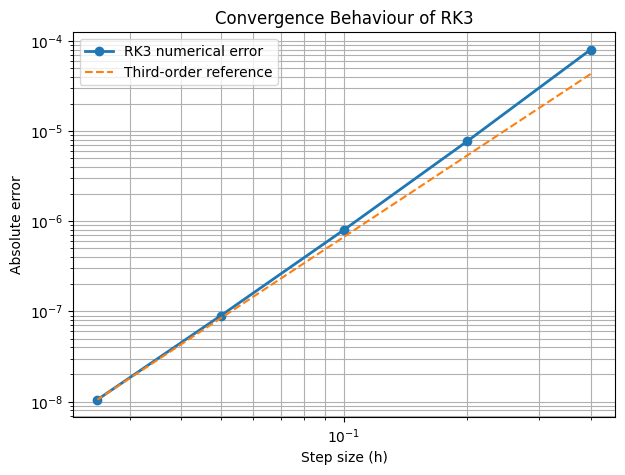

In [6]:

plt.figure(figsize=(7, 5))

plt.loglog(
    STEPS, err_rk3,
    'o-', linewidth=2,
    label='RK3 numerical error'
)

reference_line = err_rk3[-1] * (
    np.array(STEPS)/STEPS[-1]
)**3

plt.loglog(
    STEPS, reference_line,
    '--', label='Third-order reference'
)

plt.xlabel("Step size (h)")
plt.ylabel("Absolute error")
plt.title("Convergence Behaviour of RK3")

plt.grid(True, which='both')
plt.legend()
plt.show()



## 6. Numerical Solution of the Blasius Velocity Profile

The numerical solution provides three important quantities:

- $f(\eta)$: Similarity stream function.
- $f'(\eta)$: Dimensionless velocity distribution.
- $f''(\eta)$: Velocity gradient distribution.

The velocity starts from zero at the plate because of the no-slip condition and gradually approaches the free-stream value.

The boundary-layer edge can be approximately identified where the velocity reaches 99% of the free-stream velocity.


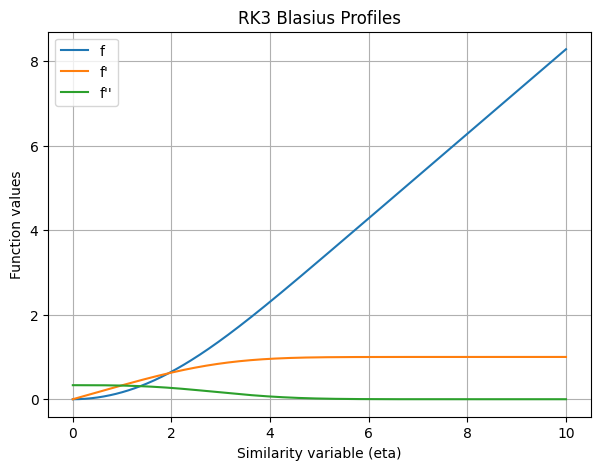

99% velocity location: 4.925000000000001
Far-field offset: 1.7207874741951787


In [7]:

def plot_profiles(method, h, name):

    s, _ = secant(h, ETA_INF, method)

    eta, Y = integrate(
        s, h, ETA_INF, method
    )

    plt.figure(figsize=(7, 5))

    plt.plot(eta, Y[:, 0], label="f")
    plt.plot(eta, Y[:, 1], label="f'")
    plt.plot(eta, Y[:, 2], label="f''")

    plt.xlabel("Similarity variable (eta)")
    plt.ylabel("Function values")
    plt.title(f"{name} Blasius Profiles")

    plt.grid(True)
    plt.legend()
    plt.show()

    indices = np.where(Y[:, 1] >= 0.99)[0]

    if len(indices) > 0:
        print(
            "99% velocity location:",
            eta[indices[0]]
        )

    print(
        "Far-field offset:",
        eta[-1] - Y[-1, 0]
    )

    return eta, Y


eta3, Y3 = plot_profiles(
    rk3, 0.025, "RK3"
)



## 7. Convergence Analysis Using RK4

The same numerical procedure is repeated using the classical fourth-order Runge-Kutta method.

The fourth-order method is expected to provide improved accuracy compared with RK3 for a similar integration step size.

Its theoretical convergence order is:

$$
e(h)\propto h^4
$$

The calculated errors and observed orders are compared with the RK3 results.


In [8]:

s_rk4, err_rk4, order_rk4 = convergence_study(
    rk4, "RK4"
)



RK4 Results
       h |           f(0) |        Error |    Order
----------------------------------------------------
   0.400 |   0.3320588158 |    1.479e-06 |        -
   0.200 |   0.3320574575 |    1.202e-07 |    3.620
   0.100 |   0.3320573456 |    8.407e-09 |    3.838
   0.050 |   0.3320573378 |    5.535e-10 |    3.925
   0.025 |   0.3320573372 |    3.548e-11 |    3.964

Estimated convergence order = 3.846


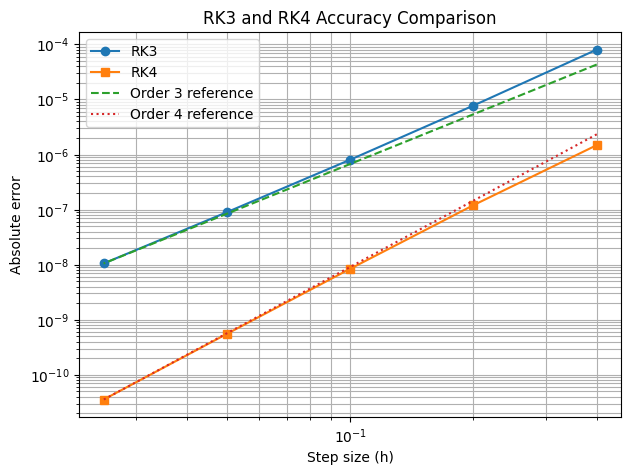

In [9]:

plt.figure(figsize=(7, 5))

plt.loglog(
    STEPS, err_rk3,
    'o-', label='RK3'
)

plt.loglog(
    STEPS, err_rk4,
    's-', label='RK4'
)

plt.loglog(
    STEPS,
    err_rk3[-1]*(np.array(STEPS)/STEPS[-1])**3,
    '--', label='Order 3 reference'
)

plt.loglog(
    STEPS,
    err_rk4[-1]*(np.array(STEPS)/STEPS[-1])**4,
    ':', label='Order 4 reference'
)

plt.xlabel("Step size (h)")
plt.ylabel("Absolute error")
plt.title("RK3 and RK4 Accuracy Comparison")

plt.grid(True, which='both')
plt.legend()
plt.show()


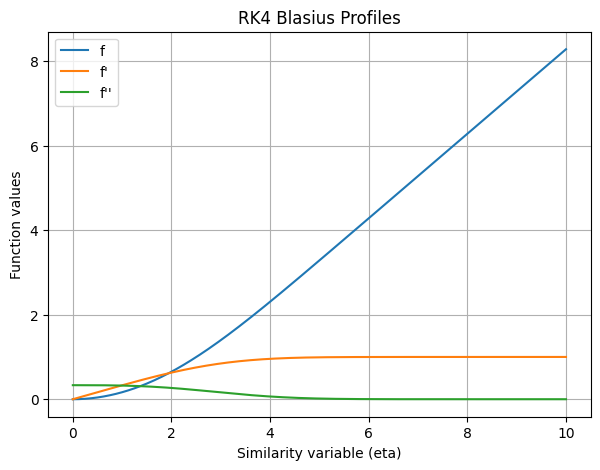

99% velocity location: 4.925000000000001
Far-field offset: 1.7207876384442464
Maximum difference in velocity profiles: 3.478e-08


In [10]:

eta4, Y4 = plot_profiles(
    rk4, 0.025, "RK4"
)

difference = np.max(
    np.abs(Y3[:, 1] - Y4[:, 1])
)

print(
    "Maximum difference in velocity profiles:",
    f"{difference:.3e}"
)



## 8. Validation with the Accepted Blasius Solution

The accepted value of the wall shear parameter for the Blasius equation is approximately:

$$
f''(0)=0.33206
$$

The calculated values obtained using RK3 and RK4 are checked against this reference.

Agreement up to three decimal places is considered satisfactory for the present assignment.


In [11]:

print(
    f"{'Method':<8} {'h':>7} "
    f"{'f''(0)':>14} {'Rounded':>10} {'Check':>8}"
)

print("-"*53)

for method_name, results in [
    ("RK3", s_rk3),
    ("RK4", s_rk4)
]:

    for h, value in zip(STEPS, results):

        rounded = round(value, 3)

        check = "PASS" if rounded == 0.332 else "CHECK"

        print(
            f"{method_name:<8} {h:7.3f} "
            f"{value:14.10f} {rounded:10.3f} "
            f"{check:>8}"
        )


Method         h           f(0)    Rounded    Check
-----------------------------------------------------
RK3        0.400   0.3319771448      0.332     PASS
RK3        0.200   0.3320495982      0.332     PASS
RK3        0.100   0.3320565334      0.332     PASS
RK3        0.050   0.3320572476      0.332     PASS
RK3        0.025   0.3320573267      0.332     PASS
RK4        0.400   0.3320588158      0.332     PASS
RK4        0.200   0.3320574575      0.332     PASS
RK4        0.100   0.3320573456      0.332     PASS
RK4        0.050   0.3320573378      0.332     PASS
RK4        0.025   0.3320573372      0.332     PASS



## 9. Results and Conclusion

The Blasius boundary-layer equation has been solved numerically using the shooting method.

The following observations are obtained:

1. The shooting method successfully determines the unknown initial value $f''(0)$.

2. The Secant method provides a convenient approach for satisfying the far-field boundary condition.

3. The RK3 method exhibits convergence behaviour close to third order.

4. The RK4 method demonstrates fourth-order convergence and provides better numerical accuracy.

5. The computed wall shear parameter approaches the accepted value:

$$
\boxed{f''(0)\approx 0.332057}
$$

6. The dimensionless velocity gradually approaches the free-stream value as the similarity coordinate increases.

Overall, both Runge-Kutta methods provide satisfactory numerical solutions. However, RK4 is more accurate for the selected step sizes.

The study also demonstrates the importance of choosing an appropriate computational domain and integration step size when solving boundary-value problems numerically.
